# ДЗ-1. Рекомендательные системы

Amazon Reviews 2023 — Musical Instruments.

In [1]:
from __future__ import annotations
import os, sys, json, random, ast, copy, gc, gzip, hashlib, pickle, time
import urllib.request
from pathlib import Path
from dataclasses import dataclass
from concurrent.futures import ThreadPoolExecutor, as_completed

ROOT = Path.cwd()
if not (ROOT / 'models').is_dir():
    raise RuntimeError('Запустите ноутбук из папки hw1.')
sys.path.insert(0, str(ROOT))
os.environ['MPLCONFIGDIR'] = str(ROOT / '.cache' / 'matplotlib')
os.environ['OPENBLAS_NUM_THREADS'] = '1'
os.environ['VECLIB_MAXIMUM_THREADS'] = '1'
os.environ['OMP_NUM_THREADS'] = '1'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy, torch
from scipy import sparse
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits

config = {'seed': 42, 'positive_rating': 4, 'k': 10, 'train_quantile': 0.7, 'validation_quantile': 0.85, 'max_items': 5000, 'min_user_history': 5, 'max_users': 30000, 'primary_metric': 'ndcg@10', 'evaluation_batch_size': 256, 'blas_threads': 1, 'torch_threads': 4}
random.seed(config['seed']); np.random.seed(config['seed']); torch.manual_seed(config['seed'])
torch.set_num_threads(config['torch_threads'])
torch.use_deterministic_algorithms(True)
blas_limit = threadpool_limits(limits=config['blas_threads'], user_api='blas')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
(ROOT / 'results' / 'figures').mkdir(parents=True, exist_ok=True)
display(pd.Series(config, name='Параметры'))


def notebook_code_hash():
    notebook = json.loads((ROOT / 'experiments.ipynb').read_text())
    digest = hashlib.sha256()
    for cell in notebook['cells']:
        if cell['cell_type'] == 'code':
            tree = ast.parse(''.join(cell['source']))
            digest.update(ast.dump(tree, include_attributes=False).encode())
    return digest.hexdigest()

Matplotlib is building the font cache; this may take a moment.


seed                          42
positive_rating                4
k                             10
train_quantile               0.7
validation_quantile         0.85
max_items                   5000
min_user_history               5
max_users                  30000
primary_metric           ndcg@10
evaluation_batch_size        256
blas_threads                   1
torch_threads                  4
Name: Параметры, dtype: object

## 1. Данные

[Amazon Reviews 2023 — Musical Instruments](https://amazon-reviews-2023.github.io/) содержит отзывы о музыкальных товарах. В файле **0-core** уже
удалены повторы, но нет отбора по активности. Пользователи и товары отбираются по train.

Поля: `user_id` — пользователь, `parent_asin` — товар, `rating` — оценка 1–5,
`timestamp` — время отзыва в миллисекундах Unix.

Рекомендуются новые товары. Оценки **4–5** считаются положительными.
Отзыв не доказывает покупку, а отсутствие отзыва не означает, что товар не нравится.

In [2]:
DATA_DIR = ROOT / "data"

SOURCE_PAGE = "https://amazon-reviews-2023.github.io/"

FILES = {
    "ratings": {
        "filename": "Musical_Instruments.csv.gz",
        "url": "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_2023/benchmark/0core/rating_only/Musical_Instruments.csv.gz",
        "sha256": "042648a89f479aaa2af4664dcb49966dbaf07bd5ebab6957799f5fb4c5efa2e0",
    },
    "metadata": {
        "filename": "meta_Musical_Instruments.jsonl.gz",
        "url": "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_2023/raw/meta_categories/meta_Musical_Instruments.jsonl.gz",
        "sha256": "26a08fb09c39f9afc0982e7c101967df23a08ccdb0832657a3fe1af89e67c29d",
    },
}

def sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(8 * 1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

def _download_ranges(url: str, part: Path, workers: int = 16):
    """Загрузить файл частями по HTTP."""
    with urllib.request.urlopen(urllib.request.Request(url, method="HEAD"), timeout=60) as response:
        size = int(response.headers["Content-Length"])
    chunk_size = 4 * 1024 * 1024
    chunks = part.parent / (part.name + ".chunks")
    chunks.mkdir(exist_ok=True)
    # Сохраняем уже загруженные полные части.
    if part.exists():
        with part.open("rb") as stream:
            for index in range(part.stat().st_size // chunk_size):
                path = chunks / str(index)
                block = stream.read(chunk_size)
                if not path.exists():
                    path.write_bytes(block)
    count = (size + chunk_size - 1) // chunk_size

    def one(index):
        begin = index * chunk_size
        end = min(size, begin + chunk_size) - 1
        target = chunks / str(index)
        if target.exists() and target.stat().st_size == end - begin + 1:
            return index
        for attempt in range(3):
            try:
                request = urllib.request.Request(url, headers={"Range": f"bytes={begin}-{end}", "User-Agent": "RecSys-Homework/1.0"})
                with urllib.request.urlopen(request, timeout=120) as response, target.open("wb") as output:
                    if response.status != 206:
                        raise IOError("Source did not honor the requested byte range")
                    while block := response.read(256 * 1024):
                        output.write(block)
                if target.stat().st_size != end - begin + 1:
                    raise IOError("Truncated byte range")
                return index
            except Exception:
                if attempt == 2:
                    raise
                time.sleep(2 ** attempt)

    with ThreadPoolExecutor(max_workers=workers) as pool:
        for done, future in enumerate(as_completed([pool.submit(one, i) for i in range(count)]), 1):
            future.result()
            if done % 8 == 0 or done == count:
                print(f"  {done}/{count} ranges cached", flush=True)
    with part.open("wb") as output:
        for index in range(count):
            with (chunks / str(index)).open("rb") as stream:
                for block in iter(lambda: stream.read(8 * 1024 * 1024), b""):
                    output.write(block)

def download_data(data_dir: Path = DATA_DIR) -> dict:
    """Скачать gzip-файлы и сохранить источники и SHA256."""
    data_dir = Path(data_dir)
    data_dir.mkdir(parents=True, exist_ok=True)
    manifest = {"source": SOURCE_PAGE, "category": "Musical_Instruments", "edition": 2023, "processing": "official deduplicated 0-core ratings, without activity-core filtering", "files": {}}
    for key, spec in FILES.items():
        path = data_dir / spec["filename"]
        if not path.exists():
            part = path.with_suffix(path.suffix + ".part")
            print(f"Downloading {key}: {spec['url']}", flush=True)
            for attempt in range(3):
                try:
                    _download_ranges(spec["url"], part)
                    # Проверяем gzip перед сохранением готового файла.
                    with gzip.open(part, "rb") as stream:
                        for _ in iter(lambda: stream.read(8 * 1024 * 1024), b""):
                            pass
                    part.replace(path)
                    break
                except Exception:
                    if attempt == 2:
                        raise
                    time.sleep(2 ** attempt)
        record = {"url": spec["url"], "filename": path.name, "bytes": path.stat().st_size, "sha256": sha256(path)}
        if record["sha256"] != spec["sha256"]:
            raise ValueError(f"Source checksum changed for {key}; inspect the source version before rerunning experiments.")
        manifest["files"][key] = record
        print(f"{key}: {record['bytes']:,} bytes, SHA256 {record['sha256']}", flush=True)
    (data_dir / "source_manifest.json").write_text(json.dumps(manifest, indent=2) + "\n")
    return manifest

In [3]:
@dataclass
class PreparedData:
    train: pd.DataFrame
    validation: pd.DataFrame
    test: pd.DataFrame
    users: np.ndarray
    items: np.ndarray
    metadata: pd.DataFrame
    summary: dict
    config: dict

    @property
    def shape(self):
        return len(self.users), len(self.items)

    def ratings(self, frame: pd.DataFrame | None = None):
        frame = self.train if frame is None else frame
        return sparse.csr_matrix(
            (frame.rating.to_numpy(dtype=np.float64), (frame.uid.to_numpy(), frame.iid.to_numpy())),
            shape=self.shape,
        )

def _metadata(path: Path, item_ids: np.ndarray) -> pd.DataFrame:
    wanted = set(item_ids)
    found = {}
    with gzip.open(path, "rt", encoding="utf-8") as stream:
        for line in stream:
            record = json.loads(line)
            item = record.get("parent_asin")
            if item not in wanted:
                continue
            details = record.get("details") or {}
            brand = details.get("Brand") or details.get("Brand Name") or record.get("store") or "UNKNOWN"
            categories = record.get("categories") or []
            categories = sorted({str(value).strip() for value in categories if isinstance(value, (str, int)) and str(value).strip()})
            found[item] = {"parent_asin": item, "title": str(record.get("title") or item), "brand": str(brand).strip() or "UNKNOWN", "categories": categories}
    rows = [found.get(item, {"parent_asin": item, "title": item, "brand": "UNKNOWN", "categories": []}) for item in item_ids]
    result = pd.DataFrame(rows)
    result.index.name = "iid"
    return result

def prepare_data(config: dict, data_dir: Path = DATA_DIR, force: bool = False) -> PreparedData:
    """Разбить по времени и выбрать пользователей и товары только по train."""
    data_dir = Path(data_dir)
    source_manifest = json.loads((data_dir / "source_manifest.json").read_text())
    identity = {"pipeline_version": 1, "pipeline_sha256": notebook_code_hash(), "config": config, "source": source_manifest}
    fingerprint = hashlib.sha256(json.dumps(identity, sort_keys=True).encode()).hexdigest()[:16]
    cache = data_dir / f"prepared_{fingerprint}.pkl"
    if cache.exists() and not force:
        with cache.open("rb") as stream:
            return pickle.load(stream)

    raw = pd.read_csv(data_dir / FILES["ratings"]["filename"], dtype={"user_id": "string", "parent_asin": "string", "rating": "float32", "timestamp": "Int64"})
    required = ["user_id", "parent_asin", "rating", "timestamp"]
    initial = {"interactions": len(raw), "users": raw.user_id.nunique(), "items": raw.parent_asin.nunique()}
    missing = raw[required].isna().sum().to_dict()
    valid = raw.dropna(subset=required)
    valid = valid.loc[valid.rating.between(1, 5) & valid.user_id.ne("") & valid.parent_asin.ne("")].copy()
    valid["timestamp"] = valid.timestamp.astype("int64")
    valid = valid.sort_values(["timestamp", "user_id", "parent_asin"], kind="stable")
    duplicate_count = int(valid.duplicated(["user_id", "parent_asin"]).sum())
    valid = valid.drop_duplicates(["user_id", "parent_asin"], keep="first")
    if valid.timestamp.max() < 10**12:
        raise ValueError("Expected documented Amazon millisecond timestamps; inspect source before continuing.")

    # Границы времени по квантилям очищенных событий.
    t1 = int(valid.timestamp.quantile(config["train_quantile"], interpolation="nearest"))
    t2 = int(valid.timestamp.quantile(config["validation_quantile"], interpolation="nearest"))
    raw_train = valid.loc[valid.timestamp < t1]
    catalog_counts = raw_train.groupby("parent_asin", sort=True).size().rename("count").reset_index()
    catalog_counts = catalog_counts.sort_values(["count", "parent_asin"], ascending=[False, True], kind="stable")
    catalog = set(catalog_counts.head(config["max_items"]).parent_asin)
    candidate_train = raw_train.loc[raw_train.parent_asin.isin(catalog)]
    user_counts = candidate_train.groupby("user_id", sort=True).size()
    users = np.array(sorted(user_counts.loc[user_counts >= config["min_user_history"]].index), dtype=str)
    before_user_cap = len(users)
    if len(users) > config["max_users"]:
        rng = np.random.default_rng(config["seed"])
        users = np.sort(rng.choice(users, config["max_users"], replace=False))
    cohort = set(users)
    selected_train = candidate_train.loc[candidate_train.user_id.isin(cohort)]
    # Оставляем товары, встречающиеся в train после отбора пользователей.
    items = np.array(sorted(selected_train.parent_asin.unique()), dtype=str)
    selected = valid.loc[valid.user_id.isin(cohort) & valid.parent_asin.isin(set(items))].copy()
    user_map = {user: i for i, user in enumerate(users)}
    item_map = {item: i for i, item in enumerate(items)}
    selected["uid"] = selected.user_id.map(user_map).astype("int32")
    selected["iid"] = selected.parent_asin.map(item_map).astype("int32")
    selected = selected[["uid", "iid", "rating", "timestamp"]].reset_index(drop=True)
    train = selected.loc[selected.timestamp < t1].reset_index(drop=True)
    validation = selected.loc[(selected.timestamp >= t1) & (selected.timestamp < t2)].reset_index(drop=True)
    test = selected.loc[selected.timestamp >= t2].reset_index(drop=True)

    assert 100_000 <= len(selected) <= 2_000_000, f"Cohort has {len(selected):,} events; adjust TRAIN-only size filters before experiments."
    assert len(users) >= 1000 and len(items) >= 1000
    assert train.timestamp.max() < validation.timestamp.min() <= validation.timestamp.max() < test.timestamp.min()
    assert train.uid.nunique() == len(users) and train.iid.nunique() == len(items)
    assert not selected.duplicated(["uid", "iid"]).any()
    metadata = _metadata(data_dir / FILES["metadata"]["filename"], items)

    summary = {
        "fingerprint": fingerprint,
        "source": source_manifest,
        "raw": {key: int(value) for key, value in initial.items()},
        "missing": {key: int(value) for key, value in missing.items()},
        "duplicate_pairs_removed": duplicate_count,
        "valid_before_cohort": len(valid),
        "train_users_before_cap": before_user_cap,
        "selected": {"interactions": len(selected), "users": len(users), "items": len(items)},
        "splits": {name: {"interactions": len(frame), "users": int(frame.uid.nunique()), "items": int(frame.iid.nunique())} for name, frame in [("train", train), ("validation", validation), ("test", test)]},
        "time_cuts_ms": {"train_end_exclusive": t1, "validation_end_exclusive": t2},
        "time_cuts_utc": {"train_end_exclusive": str(pd.to_datetime(t1, unit="ms", utc=True)), "validation_end_exclusive": str(pd.to_datetime(t2, unit="ms", utc=True))},
        "excluded_by_cohort": {"interactions": len(valid) - len(selected), "users": int(valid.user_id.nunique()) - len(users), "items": int(valid.parent_asin.nunique()) - len(items)},
        "metadata": {"missing_brand_fraction": float(metadata.brand.eq("UNKNOWN").mean()), "missing_categories_fraction": float(metadata.categories.map(len).eq(0).mean()), "distinct_brands": int(metadata.brand.nunique()), "distinct_categories": len({c for row in metadata.categories for c in row})},
        "sparsity": 1 - len(selected) / (len(users) * len(items)),
    }
    prepared = PreparedData(train, validation, test, users, items, metadata, summary, config)
    with cache.open("wb") as stream:
        pickle.dump(prepared, stream, protocol=pickle.HIGHEST_PROTOCOL)
    return prepared

def encode_item_metadata(metadata: pd.DataFrame, min_frequency: int = 2):
    """Закодировать категории и бренд/магазин товаров из train."""
    rows = []
    counts = {}
    for row in metadata.itertuples():
        features = {f"brand:{row.brand}"} | {f"category:{c}" for c in row.categories}
        rows.append(features)
        for feature in features:
            counts[feature] = counts.get(feature, 0) + 1
    vocabulary = ["UNKNOWN"] + sorted(feature for feature, count in counts.items() if count >= min_frequency)
    mapping = {feature: i for i, feature in enumerate(vocabulary)}
    rr, cc = [], []
    for i, features in enumerate(rows):
        codes = {mapping.get(feature, 0) for feature in features} or {0}
        rr.extend([i] * len(codes))
        cc.extend(sorted(codes))
    matrix = sparse.csr_matrix((np.ones(len(rr), dtype=np.float32), (rr, cc)), shape=(len(rows), len(vocabulary)))
    return matrix, vocabulary

In [4]:
manifest = download_data()
data = prepare_data(config)
display(pd.DataFrame([data.summary['raw'], data.summary['selected']], index=['Исходный 0-core', 'Итоговая выборка']))
display(pd.DataFrame(data.summary['splits']).T)
display(pd.DataFrame(manifest['files']).T[['filename', 'bytes', 'sha256']])

ratings: 75,845,845 bytes, SHA256 042648a89f479aaa2af4664dcb49966dbaf07bd5ebab6957799f5fb4c5efa2e0


metadata: 155,378,934 bytes, SHA256 26a08fb09c39f9afc0982e7c101967df23a08ccdb0832657a3fe1af89e67c29d


,interactions,users,items
Исходный 0-core,2975551,1762679,213571
Итоговая выборка,166373,20415,4849


,interactions,users,items
train,157176,20415,4849
validation,5460,3061,1906
test,3737,2227,1518


,filename,bytes,sha256
ratings,Musical_Instruments.csv.gz,75845845,042648a89f479aaa2af4664dcb49966dbaf07bd5ebab69...
metadata,meta_Musical_Instruments.jsonl.gz,155378934,26a08fb09c39f9afc0982e7c101967df23a08ccdb08326...


## 2. Анализ и подготовка

Проверяются пропуски, оценки и повторы. Для повторной пары user–item остаётся первое событие.
Границы train/validation/test заданы квантилями времени 0.70 и 0.85.

По train выбираются до 5 000 популярных товаров и пользователи с историей от пяти событий.
Лимит — 30 000 пользователей; при превышении используется случайная выборка с seed 42.
Товары без train-наблюдений после этого отбора удаляются.

Один набор ID используется для всех моделей. Малый каталог снижает затраты EASE,
но смещает выборку к популярным товарам и активным пользователям.

In [5]:
all_events = pd.concat([data.train, data.validation, data.test], ignore_index=True)
checks = {'interactions_100k_to_2m': 100_000 <= len(all_events) <= 2_000_000, 'users_at_least_1000': data.shape[0] >= 1000, 'items_at_least_1000': data.shape[1] >= 1000, 'unique_user_item_pairs': not all_events.duplicated(['uid','iid']).any(), 'chronological': data.train.timestamp.max() < data.validation.timestamp.min() and data.validation.timestamp.max() < data.test.timestamp.min()}
assert all(checks.values())
display(pd.Series(checks, name='Проверки требований'))
display(pd.Series({'missing_input_fields': data.summary['missing'], 'duplicate_pairs_removed': data.summary['duplicate_pairs_removed'], 'valid_before_cohort': data.summary['valid_before_cohort'], 'users_before_random_cap': data.summary['train_users_before_cap'], 'sparsity': data.summary['sparsity'], 'excluded_by_cohort': data.summary['excluded_by_cohort']}))

interactions_100k_to_2m    True
users_at_least_1000        True
items_at_least_1000        True
unique_user_item_pairs     True
chronological              True
Name: Проверки требований, dtype: bool

missing_input_fields       {'user_id': 0, 'parent_asin': 0, 'rating': 0, ...
duplicate_pairs_removed                                                    0
valid_before_cohort                                                  2975551
users_before_random_cap                                                20415
sparsity                                                            0.998319
excluded_by_cohort         {'interactions': 2809178, 'users': 1742264, 'i...
dtype: object

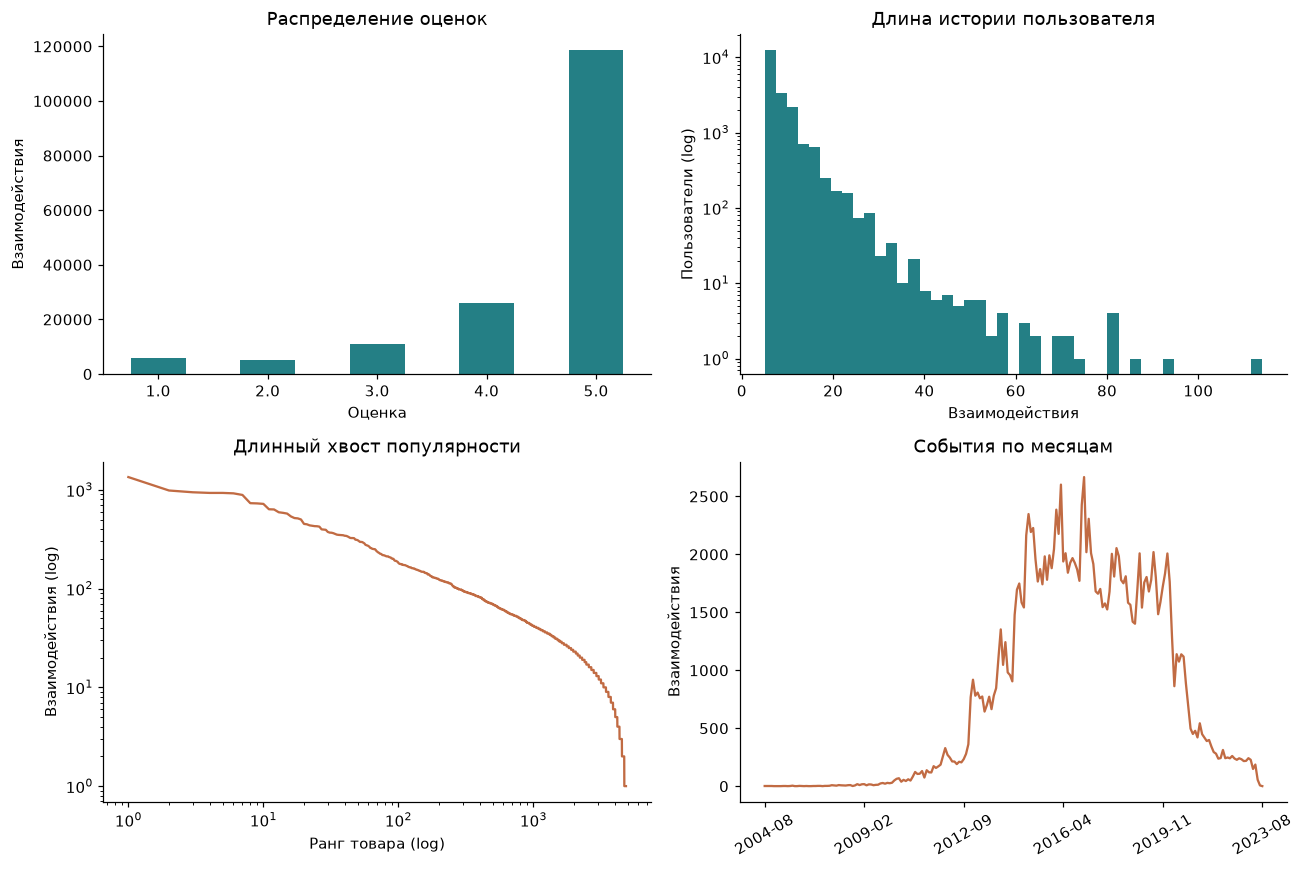

,rating
count,166373.000000
mean,4.480469
std,0.991767
min,1.000000
25%,4.000000
50%,5.000000
75%,5.000000
max,5.000000


In [6]:
user_activity = all_events.groupby('uid').size()
item_activity = all_events.groupby('iid').size().sort_values(ascending=False)
dates = pd.to_datetime(all_events.timestamp, unit='ms', utc=True).dt.tz_localize(None)
monthly = all_events.assign(month=dates.dt.to_period('M').astype(str)).groupby('month').size()
fig, axes = plt.subplots(2,2, figsize=(12,8))
all_events.rating.value_counts().sort_index().plot.bar(ax=axes[0,0], color='#247f85', rot=0)
axes[0,0].set(title='Распределение оценок', xlabel='Оценка', ylabel='Взаимодействия')
axes[0,1].hist(user_activity, bins=45, color='#247f85', log=True)
axes[0,1].set(title='Длина истории пользователя', xlabel='Взаимодействия', ylabel='Пользователи (log)')
axes[1,0].loglog(np.arange(1,len(item_activity)+1), item_activity.to_numpy(), color='#c16b43')
axes[1,0].set(title='Длинный хвост популярности', xlabel='Ранг товара (log)', ylabel='Взаимодействия (log)')
axes[1,1].plot(np.arange(len(monthly)), monthly.to_numpy(), color='#c16b43')
ticks = np.linspace(0,len(monthly)-1, min(6,len(monthly))).astype(int)
axes[1,1].set_xticks(ticks, monthly.index[ticks], rotation=30)
axes[1,1].set(title='События по месяцам', ylabel='Взаимодействия')
fig.tight_layout(); fig.savefig(ROOT/'results/figures/eda.png', bbox_inches='tight'); plt.show()
display(all_events.rating.describe().to_frame('rating'))

### Признаки для FM

К ID добавлены категории и бренд/магазин: они связывают похожие товары и общие
предпочтения. Словарь строится по каталогу train; редкие значения заменяются на `UNKNOWN`.

Итоговые рейтинги, число отзывов, helpful votes, цена, bought-together и текст
целевого отзыва не используются. Названия нужны только для примеров.

Категории и бренд считаются постоянными и известными до рекомендации.

missing_brand_fraction            0.001650
missing_categories_fraction       0.021448
distinct_brands                1410.000000
distinct_categories             397.000000
Name: Покрытие метаданными, dtype: float64

,parent_asin,title,brand,categories
iid,,,,
0,0000098906,Guiros Wooden Percussion 3 Piece Set 3 Inch Wo...,WADSUWAN SHOP,"[Drums & Percussion, Folk & World, Guiros, Han..."
1,0470536454,Crocheting for Dummies,For Dummies,"[General Accessories, Instrument Accessories, ..."
2,0634003224,Essential Elements for Band - Trombone Book 1 ...,Hal Leonard Corp. (Author),"[Band & Orchestra, Brass, Musical Instruments]"
3,0739079891,"Alfred’s Teach Yourself to Play Ukulele, Compl...",Alfred Music,"[Musical Instruments, Ukuleles, Ukuleles, Mand..."
4,0793533929,Hal Leonard Guitar Method Book 1: Bk/Online Audio,"Will Schmid (Author), Greg Koch (Author)","[Acoustic Guitars, Guitars, Musical Instruments]"


Матрица метапризнаков: (4849, 930) ненулевых: 25588


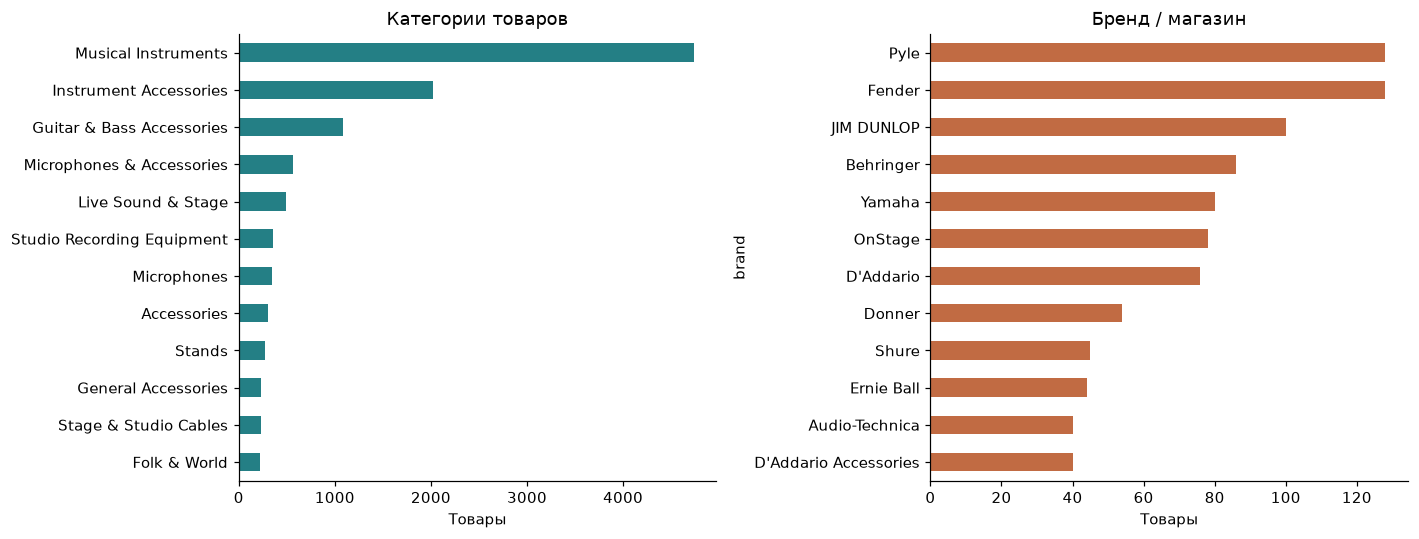

In [7]:
item_features, feature_names = encode_item_metadata(data.metadata)
display(pd.Series(data.summary['metadata'], name='Покрытие метаданными'))
display(data.metadata.head(5))
print('Матрица метапризнаков:', item_features.shape, 'ненулевых:', item_features.nnz)
category_counts = pd.Series([category for categories in data.metadata.categories for category in categories]).value_counts().head(12)
brand_counts = data.metadata.brand.value_counts().head(12)
fig, axes = plt.subplots(1,2,figsize=(13,5))
category_counts.iloc[::-1].rename(index=lambda s: s[:48]).plot.barh(ax=axes[0],color='#247f85')
brand_counts.iloc[::-1].rename(index=lambda s: s[:40]).plot.barh(ax=axes[1],color='#c16b43')
axes[0].set(title='Категории товаров',xlabel='Товары'); axes[1].set(title='Бренд / магазин',xlabel='Товары')
fig.tight_layout(); fig.savefig(ROOT/'results/figures/metadata.png',bbox_inches='tight'); plt.show()

## 3. Оценка качества

Основная метрика — **NDCG@10**, дополнительная — **Recall@10**.

Разбиение временное: train → validation → test. Настройки выбираются на validation,
затем модели обучаются на train + validation и оцениваются на test.

Кандидаты — весь каталог train без уже оценённых пользователем товаров, включая
низкие оценки. Для test учитывается история train + validation. Новые ID исключены;
общие потери при отборе показаны выше. Оцениваются пользователи с положительными
товарами в проверочной части и минимум 10 кандидатами.

Если в истории нет положительных оценок, используются популярные товары.
Для всех моделей правила одинаковы; при равных scores первым идёт меньший ID.
Релевантность: $r_{ui}\ge4$.

NDCG@10 учитывает место товара, Recall@10 — долю найденных релевантных товаров:

$$Recall@10(u)=\frac{|L_u\cap G_u|}{|G_u|},\quad
NDCG@10(u)=\frac{\sum_{r=1}^{10}rel_r/\log_2(r+1)}{\sum_{r=1}^{\min(10,|G_u|)}1/\log_2(r+1)}.$$

$L_u$ — рекомендации, $G_u$ — релевантные товары. Метрики усредняются по пользователям.
Используются все кандидаты, без случайной выборки.
Coverage@10 показывает долю товаров, попавших в рекомендации.

In [8]:
@dataclass
class RankingProtocol:
    users: np.ndarray
    ground_truth: dict[int, np.ndarray]
    seen: sparse.csr_matrix
    popularity: np.ndarray
    positive_counts: np.ndarray
    diagnostics: dict
    k: int = 10

    @property
    def fingerprint(self):
        h = hashlib.sha256(self.users.tobytes())
        for user in self.users:
            h.update(np.asarray(self.ground_truth[int(user)], dtype=np.int64).tobytes())
        h.update(self.seen.indptr.tobytes())
        h.update(self.seen.indices.tobytes())
        h.update(self.seen.data.tobytes())
        h.update(np.asarray([self.k], dtype=np.int64).tobytes())
        return h.hexdigest()[:16]

def make_protocol(history: sparse.csr_matrix, heldout: pd.DataFrame, k: int = 10) -> RankingProtocol:
    history = history.tocsr(copy=True)
    history.sort_indices()
    positive = history.copy()
    positive.data = (positive.data >= 4).astype(np.float64)
    positive.eliminate_zeros()
    positive_counts = np.diff(positive.indptr)
    popularity = np.asarray(positive.sum(axis=0)).ravel()
    truth = {}
    positive_heldout = heldout.loc[heldout.rating >= 4]
    for user, group in positive_heldout.groupby("uid", sort=True):
        user = int(user)
        seen = history.indices[history.indptr[user]:history.indptr[user + 1]]
        if not len(seen):
            continue
        unseen_truth = np.setdiff1d(group.iid.to_numpy(dtype=np.int64), seen, assume_unique=False)
        if len(unseen_truth) and history.shape[1] - len(seen) >= k:
            truth[user] = unseen_truth
    users = np.array(sorted(truth), dtype=np.int64)
    if not len(users):
        raise ValueError("No eligible users: inspect temporal split and cohort without tuning on test quality.")
    diagnostics = {
        "heldout_users": int(heldout.uid.nunique()),
        "heldout_events": len(heldout),
        "heldout_positive_events": len(positive_heldout),
        "evaluated_users": len(users),
        "excluded_users_no_eligible_positive_or_candidates": int(heldout.uid.nunique()) - len(users),
        "relevant_pairs": sum(map(len, truth.values())),
        "fallback_users_without_positive_history": int((positive_counts[users] == 0).sum()),
        "candidate_catalog": history.shape[1],
    }
    return RankingProtocol(users, truth, history, popularity, positive_counts, diagnostics, k)

def ranking_metrics(recommendations: np.ndarray, users: np.ndarray, ground_truth: dict, k: int = 10):
    recommendations = np.asarray(recommendations)
    if recommendations.shape != (len(users), k):
        raise ValueError("Expected exactly K unique recommendations per eligible user.")
    discounts = 1 / np.log2(np.arange(2, k + 2))
    recalls, ndcgs, hits = [], [], []
    for user, recs in zip(users, recommendations):
        relevant = np.asarray(ground_truth[int(user)])
        if len(relevant) == 0 or len(np.unique(recs)) != k:
            raise ValueError("Ground truth must be nonempty and recommendation IDs unique.")
        hit = np.isin(recs, relevant)
        recalls.append(float(hit.sum() / len(relevant)))
        ndcgs.append(float(hit @ discounts / discounts[:min(k, len(relevant))].sum()))
        hits.append(float(hit.any()))
    return {f"ndcg@{k}": float(np.mean(ndcgs)), f"recall@{k}": float(np.mean(recalls)), f"hit_rate@{k}": float(np.mean(hits)), "users": len(users)}, {"ndcg": np.asarray(ndcgs), "recall": np.asarray(recalls)}

def evaluate(model, protocol: RankingProtocol, batch_size: int = 256, return_recommendations: bool = False):
    start = time.perf_counter()
    predictions = []
    for offset in range(0, len(protocol.users), batch_size):
        users = protocol.users[offset:offset + batch_size]
        scores = np.asarray(model.score_users(users), dtype=np.float64)
        if scores.shape != (len(users), protocol.seen.shape[1]) or not np.isfinite(scores).all():
            raise ValueError("Model returned non-finite or incorrectly shaped full-catalog scores.")
        scores = scores.copy()
        no_positives = protocol.positive_counts[users] == 0
        scores[no_positives] = protocol.popularity
        for row, user in enumerate(users):
            start_i, end_i = protocol.seen.indptr[user:user + 2]
            scores[row, protocol.seen.indices[start_i:end_i]] = -np.inf
        # При равных прогнозах выбираем меньший ID.
        topk = np.argsort(-scores, axis=1, kind="stable")[:, :protocol.k]
        predictions.append(topk)
    recs = np.concatenate(predictions)
    metrics, per_user = ranking_metrics(recs, protocol.users, protocol.ground_truth, protocol.k)
    metrics.update({"coverage@10": float(np.unique(recs).size / protocol.seen.shape[1]), "evaluation_seconds": time.perf_counter() - start, "protocol": protocol.fingerprint})
    result = {"metrics": metrics, "per_user": per_user}
    if return_recommendations:
        result["recommendations"] = recs
    return result

class Popularity:
    def fit(self, ratings):
        positive = ratings.copy()
        positive.data = (positive.data >= 4).astype(float)
        positive.eliminate_zeros()
        self.scores_ = np.asarray(positive.sum(axis=0)).ravel()
        return self

    def score_users(self, user_ids):
        return np.broadcast_to(self.scores_, (len(user_ids), len(self.scores_)))

In [9]:
train_ratings = data.ratings()
validation_protocol = make_protocol(train_ratings, data.validation, k=config['k'])
display(pd.Series(data.summary['time_cuts_utc'], name='Границы UTC, правая исключается'))
display(pd.Series(validation_protocol.diagnostics, name='Оценка на validation'))
pop_validation = evaluate(Popularity().fit(train_ratings), validation_protocol)['metrics']
display(pd.Series({key: pop_validation[key] for key in ['ndcg@10','recall@10','coverage@10']}, name='Популярность: validation'))

train_end_exclusive         2020-10-19 23:54:30.790000+00:00
validation_end_exclusive    2021-12-09 21:26:48.137000+00:00
Name: Границы UTC, правая исключается, dtype: str

heldout_users                                        3061
heldout_events                                       5460
heldout_positive_events                              4560
evaluated_users                                      2643
excluded_users_no_eligible_positive_or_candidates     418
relevant_pairs                                       4560
fallback_users_without_positive_history                 2
candidate_catalog                                    4849
Name: Оценка на validation, dtype: int64

ndcg@10        0.024121
recall@10      0.040531
coverage@10    0.003918
Name: Популярность: validation, dtype: float64

## 4. Модели и подбор настроек

Пять моделей реализованы в `models/` на NumPy/SciPy и PyTorch.
Проверяются 9 настроек ItemKNN, 6 iALS, 4 EASE, 4 FM и 6 custom ALS — всего 29.

Выбор — по validation NDCG@10; при равенстве берётся первая настройка из списка.
Test в подборе не участвует. Параметры и результаты сохраняются в журнал.

In [10]:
def _json_default(value):
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, np.ndarray):
        return value.tolist()
    raise TypeError(type(value).__name__)

def write_json(path: Path, value):
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2, default=_json_default) + "\n")
    temporary.replace(path)

def _write_model(path: Path, model):
    temporary = path.with_suffix(path.suffix + ".tmp")
    with temporary.open("wb") as stream:
        pickle.dump(model, stream, protocol=pickle.HIGHEST_PROTOCOL)
    temporary.replace(path)

def _read_model(path: Path):
    try:
        with path.open("rb") as stream:
            return pickle.load(stream)
    except (OSError, EOFError, pickle.UnpicklingError, AttributeError):
        return None

class ExperimentRunner:
    """Настройки выбираются только по validation."""

    def __init__(self, prepared, item_features, results_dir: Path = ROOT / "results", cache_dir: Path | None = None):
        self.data = prepared
        self.features = item_features
        self.results_dir = Path(results_dir)
        self.results_dir.mkdir(exist_ok=True, parents=True)
        self.cache_dir = Path(cache_dir) if cache_dir is not None else ROOT / "data" / "model_cache"
        self.cache_dir.mkdir(exist_ok=True, parents=True)
        self.ratings = prepared.ratings()
        self.validation_protocol = make_protocol(self.ratings, prepared.validation, k=prepared.config["k"])
        self.batch_size = prepared.config["evaluation_batch_size"]
        code = hashlib.sha256()
        code.update(notebook_code_hash().encode())
        for path in sorted((ROOT / "models").glob("*.py")):
            code.update(path.read_bytes())
        feature_hash = hashlib.sha256()
        for values in [np.asarray(item_features.shape, dtype=np.int64), item_features.indptr, item_features.indices, item_features.data]:
            feature_hash.update(values.tobytes())
        self.identity = {"data": prepared.summary["fingerprint"], "code": code.hexdigest(), "features": feature_hash.hexdigest(), "validation_protocol": self.validation_protocol.fingerprint, "primary_metric": "ndcg@10", "seed": prepared.config["seed"]}
        self.identity_id = hashlib.sha256(json.dumps(self.identity, sort_keys=True).encode()).hexdigest()[:16]
        self.journal_path = self.results_dir / "validation_trials.json"
        self.journal = {"identity": self.identity, "trials": [], "selected": {}}
        if self.journal_path.exists():
            previous = json.loads(self.journal_path.read_text())
            if previous.get("identity") == self.identity:
                self.journal = previous
        self.best_models = {}

    def _make_model(self, name: str, params: dict):
        constructors = {"ItemKNN": ItemKNN, "EASE": EASE, "IALS": IALS, "FM": FactorizationMachine, "CustomALS": CustomALS}
        return constructors[name](**params)

    def _fit(self, name, params, ratings, validation_callback=None):
        model = self._make_model(name, params)
        if name == "FM":
            model.fit(ratings, item_features=self.features, validation_callback=validation_callback)
        else:
            model.fit(ratings)
        return model

    def search_space(self, name):
        seed = self.data.config["seed"]
        if name == "ItemKNN":
            return [{"k": k, "shrinkage": shrink} for k in [20, 50, 100] for shrink in [0, 10, 50]]
        if name == "EASE":
            return [{"regularization": value} for value in [10., 100., 1000., 10000.]]
        if name == "IALS":
            combinations = [(32, .1, 5, 10), (32, .1, 20, 10), (32, .1, 100, 10), (32, 1., 20, 10), (64, .1, 20, 10), (32, .01, 20, 20)]
            return [{"factors": f, "regularization": r, "alpha": a, "iterations": it, "seed": seed} for f, r, a, it in combinations]
        if name == "FM":
            return [{"factors": f, "learning_rate": lr, "regularization": reg, "epochs": 12, "batch_size": 4096, "seed": seed, "use_metadata": True} for f, lr, reg in [(16, .003, 1e-4), (16, .003, 1e-5), (32, .003, 1e-4), (16, .001, 1e-4)]]
        if name == "CustomALS":
            base = self.journal["selected"]["IALS"]["params"]
            combinations = [(32, .01, 10), (32, .1, 10), (32, 1., 10), (64, .1, 10), (32, .1, 20)]
            spaces = [dict(base, factors=f, regularization=r, iterations=it, rho=.25, kappa=10.) for f, r, it in combinations]
            matched = dict(base, rho=.25, kappa=10.)
            if matched not in spaces:
                spaces.append(matched)
            return spaces
        raise ValueError(name)

    def tune(self, name: str):
        space = self.search_space(name)
        space_id = hashlib.sha256(json.dumps(space, sort_keys=True).encode()).hexdigest()[:10]
        cache = self.cache_dir / f"{name}_{self.identity_id}_{space_id}.pkl"
        if name in self.journal["selected"] and self.journal["selected"][name].get("space_id") == space_id and cache.exists():
            restored = _read_model(cache)
            if restored is not None:
                self.best_models[name] = restored
                return self.trials_table(name)

        # Пропускаем завершённые запуски из журнала.
        previous = [row for row in self.journal["trials"] if row["family"] == name and row.get("space_id") == space_id]
        best_row = max(previous, key=lambda row: (row["ndcg@10"], -row["trial_index"])) if previous else None
        best_model = None
        for index, params in enumerate(space):
            completed = next((row for row in previous if row["params"] == params), None)
            if completed is not None:
                continue
            print(f"{name} {index + 1}/{len(space)}: {params}", flush=True)
            start = time.perf_counter()
            callback = (lambda model: evaluate(model, self.validation_protocol, self.batch_size)["metrics"]["ndcg@10"]) if name == "FM" else None
            model = self._fit(name, params, self.ratings, callback)
            fit_seconds = time.perf_counter() - start
            measured = evaluate(model, self.validation_protocol, self.batch_size)["metrics"]
            row = {"family": name, "trial_index": index, "space_id": space_id, "params": params, "fit_seconds": fit_seconds, **measured}
            if hasattr(model, "best_epoch_"):
                row["selected_epochs"] = int(model.best_epoch_)
            if hasattr(model, "objective_history_"):
                row["objective_history"] = model.objective_history_
            if hasattr(model, "history_") and isinstance(model.history_, list):
                row["epoch_history"] = model.history_
            self.journal["trials"].append(row)
            print(f"  validation NDCG@10={measured['ndcg@10']:.6f}, Recall@10={measured['recall@10']:.6f}, fit={fit_seconds:.1f}s", flush=True)
            if best_row is None or measured["ndcg@10"] > best_row["ndcg@10"]:
                best_row, best_model = row, model
                _write_model(cache, model)
            else:
                del model
            write_json(self.journal_path, self.journal)
            gc.collect()
        if best_model is None:
            best_model = _read_model(cache)
            if best_model is None:
                callback = (lambda model: evaluate(model, self.validation_protocol, self.batch_size)["metrics"]["ndcg@10"]) if name == "FM" else None
                best_model = self._fit(name, best_row["params"], self.ratings, callback)
                _write_model(cache, best_model)
        self.journal["selected"][name] = copy.deepcopy(best_row)
        self.best_models[name] = best_model
        write_json(self.journal_path, self.journal)
        return self.trials_table(name)

    def trials_table(self, family=None):
        rows = self.journal["trials"]
        if family:
            rows = [row for row in rows if row["family"] == family]
        columns = ["family", "trial_index", "ndcg@10", "recall@10", "coverage@10", "fit_seconds", "params"]
        return pd.DataFrame(rows)[columns].sort_values(["family", "ndcg@10"], ascending=[True, False]).reset_index(drop=True)

    def _ablation_specs(self):
        base_params = self.journal["selected"]["IALS"]["params"]
        fm_params = dict(self.journal["selected"]["FM"]["params"])
        fm_params["epochs"] = self.journal["selected"]["FM"]["selected_epochs"]
        variants = {
            "FM_ID_only_matched": ("FM", dict(fm_params, use_metadata=False)),
            "ALS_absolute_matched": ("CustomALS", dict(base_params, rho=0., kappa=10.)),
            "ALS_custom_matched": ("CustomALS", dict(base_params, rho=.25, kappa=10.)),
        }
        return variants

    def validation_ablations(self):
        variants = self._ablation_specs()
        rows = []
        self.ablation_specs = variants
        existing = self.journal.get("ablations", [])
        if len(existing) == len(variants) and all(any(row["model"] == label and row["family"] == family and row["params"] == params for row in existing) for label, (family, params) in variants.items()):
            return pd.DataFrame(existing)
        for label, (family, params) in variants.items():
            start = time.perf_counter()
            model = self._fit(family, params, self.ratings)
            measured = evaluate(model, self.validation_protocol, self.batch_size)["metrics"]
            rows.append({"model": label, "family": family, "params": params, "fit_seconds": time.perf_counter() - start, **measured})
            print(f"{label}: validation NDCG@10={measured['ndcg@10']:.6f}", flush=True)
        self.journal["ablations"] = rows
        write_json(self.journal_path, self.journal)
        return pd.DataFrame(rows)

    def final_test(self, use_cache=True):
        required = {"ItemKNN", "EASE", "IALS", "FM", "CustomALS"}
        if not required <= self.journal["selected"].keys() or "ablations" not in self.journal:
            raise RuntimeError("Freeze all five validation selections and predefined ablations before final test.")
        expected = self._ablation_specs()
        ablations = self.journal["ablations"]
        if len(ablations) != len(expected) or not all(any(row["model"] == label and row["family"] == family and row["params"] == params for row in ablations) for label, (family, params) in expected.items()):
            raise RuntimeError("Recompute validation ablations after changes to selected base/FМ configurations.")
        selection = {"selected": self.journal["selected"], "ablations": self.journal["ablations"]}
        selection_id = hashlib.sha256(json.dumps(selection, sort_keys=True, default=_json_default).encode()).hexdigest()
        final_path = self.results_dir / "final_test.json"
        if use_cache and final_path.exists():
            previous = json.loads(final_path.read_text())
            if previous.get("identity") == self.identity and previous.get("selection_id") == selection_id:
                pd.DataFrame(previous["rows"]).to_csv(self.results_dir / "test_metrics.csv", index=False)
                pd.DataFrame(previous["paired_bootstrap"]).to_csv(self.results_dir / "paired_bootstrap.csv", index=False)
                return previous
        history = self.data.ratings(pd.concat([self.data.train, self.data.validation], ignore_index=True))
        protocol = make_protocol(history, self.data.test, k=self.data.config["k"])
        specs = [("Popularity", "Popularity", {})]
        for name in ["ItemKNN", "IALS", "EASE", "FM", "CustomALS"]:
            row = self.journal["selected"][name]
            params = dict(row["params"])
            if name == "FM":
                params["epochs"] = row["selected_epochs"]
            specs.append((name, name, params))
        specs.extend((row["model"], row["family"], row["params"]) for row in self.journal["ablations"])
        rows, scores, recommendations = [], {}, {}
        for label, family, params in specs:
            print(f"FINAL refit/evaluate: {label}", flush=True)
            start = time.perf_counter()
            model = Popularity().fit(history) if family == "Popularity" else self._fit(family, params, history)
            fit_seconds = time.perf_counter() - start
            result = evaluate(model, protocol, self.batch_size, return_recommendations=True)
            rows.append({"model": label, "family": family, "params": params, "fit_seconds": fit_seconds, **result["metrics"]})
            scores[label] = result["per_user"]["ndcg"]
            recommendations[label] = result["recommendations"][:3].tolist()
            print(f"  NDCG@10={rows[-1]['ndcg@10']:.6f}, Recall@10={rows[-1]['recall@10']:.6f}", flush=True)
            del model
            gc.collect()
        paired = []
        rng = np.random.default_rng(self.data.config["seed"])
        for name, left, right in [("metadata_effect", "FM", "FM_ID_only_matched"), ("custom_target_matched_effect", "ALS_custom_matched", "IALS"), ("personal_calibration_effect", "ALS_custom_matched", "ALS_absolute_matched")]:
            differences = scores[left] - scores[right]
            boot = np.array([rng.choice(differences, len(differences), replace=True).mean() for _ in range(2000)])
            paired.append({"comparison": name, "left": left, "right": right, "mean_ndcg_difference": float(differences.mean()), "ci95_low": float(np.quantile(boot, .025)), "ci95_high": float(np.quantile(boot, .975)), "unit": "user", "bootstrap_samples": 2000})
        final = {"identity": self.identity, "selection_id": selection_id, "protocol": protocol.diagnostics, "protocol_fingerprint": protocol.fingerprint, "rows": rows, "paired_bootstrap": paired, "example_user_ids": protocol.users[:3].tolist(), "example_recommendations": recommendations}
        write_json(final_path, final)
        pd.DataFrame(rows).to_csv(self.results_dir / "test_metrics.csv", index=False)
        pd.DataFrame(paired).to_csv(self.results_dir / "paired_bootstrap.csv", index=False)
        return final

In [11]:
from models.item_knn import ItemKNN
from models.ials import IALS
from models.ease import EASE
from models.fm import FactorizationMachine
from models.custom_als import CustomALS
runner = ExperimentRunner(data, item_features)
search_spaces = {name: runner.search_space(name) for name in ['ItemKNN','EASE','IALS','FM']}
for name, space in search_spaces.items():
    print(name, json.dumps(space, ensure_ascii=False))

ItemKNN [{"k": 20, "shrinkage": 0}, {"k": 20, "shrinkage": 10}, {"k": 20, "shrinkage": 50}, {"k": 50, "shrinkage": 0}, {"k": 50, "shrinkage": 10}, {"k": 50, "shrinkage": 50}, {"k": 100, "shrinkage": 0}, {"k": 100, "shrinkage": 10}, {"k": 100, "shrinkage": 50}]
EASE [{"regularization": 10.0}, {"regularization": 100.0}, {"regularization": 1000.0}, {"regularization": 10000.0}]
IALS [{"factors": 32, "regularization": 0.1, "alpha": 5, "iterations": 10, "seed": 42}, {"factors": 32, "regularization": 0.1, "alpha": 20, "iterations": 10, "seed": 42}, {"factors": 32, "regularization": 0.1, "alpha": 100, "iterations": 10, "seed": 42}, {"factors": 32, "regularization": 1.0, "alpha": 20, "iterations": 10, "seed": 42}, {"factors": 64, "regularization": 0.1, "alpha": 20, "iterations": 10, "seed": 42}, {"factors": 32, "regularization": 0.01, "alpha": 20, "iterations": 20, "seed": 42}]
FM [{"factors": 16, "learning_rate": 0.003, "regularization": 0.0001, "epochs": 12, "batch_size": 4096, "seed": 42, "u

### 4.1. ItemKNN

$A_{ui}=1[r_{ui}\ge4]$. Косинусное сходство товаров уменьшается при малом числе
общих положительных пользователей $n_{ij}$:
$s_{ij}=cos(i,j)n_{ij}/(n_{ij}+\beta)$.

Самосходство равно нулю. Для каждого товара остаются K соседей.
Оценка: $s_{ui}=\sum_j A_{uj}s_{ji}$.

In [12]:
display(runner.tune('ItemKNN'))

ItemKNN 1/9: {'k': 20, 'shrinkage': 0}


  validation NDCG@10=0.012827, Recall@10=0.021503, fit=0.1s


ItemKNN 2/9: {'k': 20, 'shrinkage': 10}


  validation NDCG@10=0.022423, Recall@10=0.037109, fit=0.1s


ItemKNN 3/9: {'k': 20, 'shrinkage': 50}


...

ItemKNN 8/9: {'k': 100, 'shrinkage': 10}


  validation NDCG@10=0.026192, Recall@10=0.040857, fit=0.1s


ItemKNN 9/9: {'k': 100, 'shrinkage': 50}


  validation NDCG@10=0.026968, Recall@10=0.042675, fit=0.1s


,family,trial_index,ndcg@10,recall@10,coverage@10,fit_seconds,params
0,ItemKNN,8,0.026968,0.042675,0.421943,0.064578,"{'k': 100, 'shrinkage': 50}"
1,ItemKNN,5,0.026203,0.040543,0.443803,0.063701,"{'k': 50, 'shrinkage': 50}"
2,ItemKNN,7,0.026192,0.040857,0.471644,0.064760,"{'k': 100, 'shrinkage': 10}"
3,ItemKNN,4,0.024863,0.039056,0.494329,0.063681,"{'k': 50, 'shrinkage': 10}"
4,ItemKNN,2,0.024379,0.039054,0.483811,0.063212,"{'k': 20, 'shrinkage': 50}"
5,ItemKNN,1,0.022423,0.037109,0.526294,0.062495,"{'k': 20, 'shrinkage': 10}"
6,ItemKNN,6,0.015276,0.025640,0.812126,0.065205,"{'k': 100, 'shrinkage': 0}"
7,ItemKNN,3,0.014060,0.023317,0.785523,0.063927,"{'k': 50, 'shrinkage': 0}"
8,ItemKNN,0,0.012827,0.021503,0.762838,0.062844,"{'k': 20, 'shrinkage': 0}"


### 4.2. iALS

Цель — $p_{ui}=1[r_{ui}\ge4]$. Вес ошибки — $c_{ui}=1+\alpha O_{ui}$,
где $O_{ui}=1$ для любой известной оценки. У низких оценок цель равна нулю,
но вес выше, чем у неизвестных пар. Цель неизвестных пар — ноль.

$$\min_{X,Y}\sum_{ui}c_{ui}(p_{ui}-x_u^Ty_i)^2+\lambda(\|X\|_F^2+\|Y\|_F^2).$$
$$(Y^TC_uY+\lambda I)x_u=Y^TC_up_u.$$

Факторы пользователей и товаров обновляются по очереди через `solve`.
Плотная матрица user×item не создаётся.

In [13]:
display(runner.tune('IALS'))

IALS 1/6: {'factors': 32, 'regularization': 0.1, 'alpha': 5, 'iterations': 10, 'seed': 42}


  validation NDCG@10=0.023711, Recall@10=0.036807, fit=5.7s


IALS 2/6: {'factors': 32, 'regularization': 0.1, 'alpha': 20, 'iterations': 10, 'seed': 42}


  validation NDCG@10=0.022882, Recall@10=0.037277, fit=5.7s


IALS 3/6: {'factors': 32, 'regularization': 0.1, 'alpha': 100, 'iterations': 10, 'seed': 42}


...

IALS 5/6: {'factors': 64, 'regularization': 0.1, 'alpha': 20, 'iterations': 10, 'seed': 42}


  validation NDCG@10=0.022596, Recall@10=0.035666, fit=9.8s


IALS 6/6: {'factors': 32, 'regularization': 0.01, 'alpha': 20, 'iterations': 20, 'seed': 42}


  validation NDCG@10=0.024471, Recall@10=0.042104, fit=11.3s


,family,trial_index,ndcg@10,recall@10,coverage@10,fit_seconds,params
0,IALS,5,0.024471,0.042104,0.129717,11.279084,"{'factors': 32, 'regularization': 0.01, 'alpha..."
1,IALS,0,0.023711,0.036807,0.076304,5.748574,"{'factors': 32, 'regularization': 0.1, 'alpha'..."
2,IALS,3,0.022897,0.036839,0.126830,5.731343,"{'factors': 32, 'regularization': 1.0, 'alpha'..."
3,IALS,1,0.022882,0.037277,0.126624,5.679281,"{'factors': 32, 'regularization': 0.1, 'alpha'..."
4,IALS,4,0.022596,0.035666,0.210353,9.838241,"{'factors': 64, 'regularization': 0.1, 'alpha'..."
5,IALS,2,0.017175,0.028894,0.232213,5.739991,"{'factors': 32, 'regularization': 0.1, 'alpha'..."


### 4.3. EASE

$$\min_B\|A-AB\|_F^2+\lambda\|B\|_F^2,\quad diag(B)=0.$$

$P=(A^TA+\lambda I)^{-1}$, $B_{ij}=-P_{ij}/P_{jj}$ при $i\ne j$, $B_{jj}=0$.
Оценки — $AB$. Используется разложение Холецкого.

In [14]:
display(runner.tune('EASE'))

EASE 1/4: {'regularization': 10.0}


  validation NDCG@10=0.023451, Recall@10=0.038125, fit=1.0s


EASE 2/4: {'regularization': 100.0}


  validation NDCG@10=0.029804, Recall@10=0.049853, fit=1.0s


EASE 3/4: {'regularization': 1000.0}


  validation NDCG@10=0.032518, Recall@10=0.049759, fit=1.0s


EASE 4/4: {'regularization': 10000.0}


  validation NDCG@10=0.031646, Recall@10=0.046074, fit=1.0s


,family,trial_index,ndcg@10,recall@10,coverage@10,fit_seconds,params
0,EASE,2,0.032518,0.049759,0.187668,1.019923,{'regularization': 1000.0}
1,EASE,3,0.031646,0.046074,0.149928,1.002831,{'regularization': 10000.0}
2,EASE,1,0.029804,0.049853,0.280264,1.005615,{'regularization': 100.0}
3,EASE,0,0.023451,0.038125,0.459270,1.011766,{'regularization': 10.0}


### 4.4. FM с метаданными

$$s(z)=w_0+\sum_jw_jz_j+\sum_{j<k}\langle v_j,v_k\rangle z_jz_k.$$

$z$ содержит ID пользователя и товара, категории и бренд/магазин.
Обучение — BCE с целью $1[r\ge4]$ и L2-регуляризацией.
Оценки 1–3 — отрицательные примеры; неизвестные пары не участвуют в обучении.

Взаимодействия вычисляются за $O(nnz(z)\cdot d)$.
Лучшая эпоха выбирается по validation NDCG@10.

In [15]:
display(runner.tune('FM'))
display(pd.DataFrame(runner.best_models['FM'].history_))

FM 1/4: {'factors': 16, 'learning_rate': 0.003, 'regularization': 0.0001, 'epochs': 12, 'batch_size': 4096, 'seed': 42, 'use_metadata': True}


  validation NDCG@10=0.007730, Recall@10=0.014678, fit=7.7s


FM 2/4: {'factors': 16, 'learning_rate': 0.003, 'regularization': 1e-05, 'epochs': 12, 'batch_size': 4096, 'seed': 42, 'use_metadata': True}


  validation NDCG@10=0.004697, Recall@10=0.007158, fit=8.2s


FM 3/4: {'factors': 32, 'learning_rate': 0.003, 'regularization': 0.0001, 'epochs': 12, 'batch_size': 4096, 'seed': 42, 'use_metadata': True}


  validation NDCG@10=0.008430, Recall@10=0.013067, fit=7.9s


FM 4/4: {'factors': 16, 'learning_rate': 0.001, 'regularization': 0.0001, 'epochs': 12, 'batch_size': 4096, 'seed': 42, 'use_metadata': True}


  validation NDCG@10=0.008362, Recall@10=0.016318, fit=7.6s


,family,trial_index,ndcg@10,recall@10,coverage@10,fit_seconds,params
0,FM,2,0.008430,0.013067,0.005362,7.910651,"{'factors': 32, 'learning_rate': 0.003, 'regul..."
1,FM,3,0.008362,0.016318,0.005774,7.642907,"{'factors': 16, 'learning_rate': 0.001, 'regul..."
2,FM,0,0.007730,0.014678,0.006187,7.659593,"{'factors': 16, 'learning_rate': 0.003, 'regul..."
3,FM,1,0.004697,0.007158,0.006806,8.249992,"{'factors': 16, 'learning_rate': 0.003, 'regul..."


,epoch,loss,bce,validation_metric
0,1,0.467329,0.457228,0.008430
1,2,0.368813,0.350649,0.007363
2,3,0.359911,0.339621,0.004709
3,4,0.356139,0.333766,0.005469
4,5,0.353729,0.329686,0.004247
5,6,0.352056,0.326678,0.003892
6,7,0.350182,0.323540,0.004615
7,8,0.348725,0.320948,0.003277
8,9,0.347204,0.318359,0.003713
9,10,0.345307,0.315328,0.005183


### 4.5. ALS с новым целевым сигналом

Идея — учесть и сам рейтинг, и привычку пользователя ставить высокие или низкие оценки:

$$\mu_u^{(-i)}=\frac{\sum_{j\ne i}r_{uj}+\kappa\mu_{train}}{n_u-1+\kappa},\qquad
t_{ui}=(1-\rho)\frac{r_{ui}-3}{2}+\rho\frac{r_{ui}-\mu_u^{(-i)}}{4}.$$

$\rho=0.25$, $\kappa=10$; для неизвестных пар $t_{ui}=0$.
Текущая оценка исключается из среднего пользователя. Все средние считаются по train,
при переобучении — по train + validation.

В iALS цель $p$ заменяется на $t$. Веса ошибок и alpha остаются прежними,
а правая часть уравнения становится $Y^TC_ut_u$.
Размерность факторов, регуляризация и число итераций подбираются на validation.

In [16]:
print('Custom search:', json.dumps(runner.search_space('CustomALS'), ensure_ascii=False))
display(runner.tune('CustomALS'))

Custom search: [{"factors": 32, "regularization": 0.01, "alpha": 20, "iterations": 10, "seed": 42, "rho": 0.25, "kappa": 10.0}, {"factors": 32, "regularization": 0.1, "alpha": 20, "iterations": 10, "seed": 42, "rho": 0.25, "kappa": 10.0}, {"factors": 32, "regularization": 1.0, "alpha": 20, "iterations": 10, "seed": 42, "rho": 0.25, "kappa": 10.0}, {"factors": 64, "regularization": 0.1, "alpha": 20, "iterations": 10, "seed": 42, "rho": 0.25, "kappa": 10.0}, {"factors": 32, "regularization": 0.1, "alpha": 20, "iterations": 20, "seed": 42, "rho": 0.25, "kappa": 10.0}, {"factors": 32, "regularization": 0.01, "alpha": 20, "iterations": 20, "seed": 42, "rho": 0.25, "kappa": 10.0}]
CustomALS 1/6: {'factors': 32, 'regularization': 0.01, 'alpha': 20, 'iterations': 10, 'seed': 42, 'rho': 0.25, 'kappa': 10.0}


  validation NDCG@10=0.020146, Recall@10=0.035219, fit=5.6s


CustomALS 2/6: {'factors': 32, 'regularization': 0.1, 'alpha': 20, 'iterations': 10, 'seed': 42, 'rho': 0.25, 'kappa': 10.0}


  validation NDCG@10=0.019751, Recall@10=0.034431, fit=5.5s


CustomALS 3/6: {'factors': 32, 'regularization': 1.0, 'alpha': 20, 'iterations': 10, 'seed': 42, 'rho': 0.25, 'kappa': 10.0}


...

CustomALS 5/6: {'factors': 32, 'regularization': 0.1, 'alpha': 20, 'iterations': 20, 'seed': 42, 'rho': 0.25, 'kappa': 10.0}


  validation NDCG@10=0.020755, Recall@10=0.035612, fit=11.2s


CustomALS 6/6: {'factors': 32, 'regularization': 0.01, 'alpha': 20, 'iterations': 20, 'seed': 42, 'rho': 0.25, 'kappa': 10.0}


  validation NDCG@10=0.021195, Recall@10=0.035896, fit=11.3s


,family,trial_index,ndcg@10,recall@10,coverage@10,fit_seconds,params
0,CustomALS,5,0.021195,0.035896,0.125799,11.313876,"{'factors': 32, 'regularization': 0.01, 'alpha..."
1,CustomALS,4,0.020755,0.035612,0.126418,11.239938,"{'factors': 32, 'regularization': 0.1, 'alpha'..."
2,CustomALS,0,0.020146,0.035219,0.123943,5.583712,"{'factors': 32, 'regularization': 0.01, 'alpha..."
3,CustomALS,2,0.019866,0.034548,0.124149,5.625631,"{'factors': 32, 'regularization': 1.0, 'alpha'..."
4,CustomALS,1,0.019751,0.034431,0.124149,5.546085,"{'factors': 32, 'regularization': 0.1, 'alpha'..."
5,CustomALS,3,0.019465,0.030635,0.197567,9.462216,"{'factors': 64, 'regularization': 0.1, 'alpha'..."


### Проверка признаков и целевого сигнала

FM сравнивается с вариантом без метаданных при тех же настройках и числе эпох.
Для ALS сравниваются бинарная цель, `(r-3)/2` и полный новый сигнал.
Остальные настройки ALS, включая веса ошибок, одинаковы.

FM_ID_only_matched: validation NDCG@10=0.011150


ALS_absolute_matched: validation NDCG@10=0.021851


ALS_custom_matched: validation NDCG@10=0.021195


,model,ndcg@10,recall@10,coverage@10,params
0,FM_ID_only_matched,0.011150,0.017483,0.004331,"{'factors': 32, 'learning_rate': 0.003, 'regul..."
1,ALS_absolute_matched,0.021851,0.038516,0.127861,"{'factors': 32, 'regularization': 0.01, 'alpha..."
2,ALS_custom_matched,0.021195,0.035896,0.125799,"{'factors': 32, 'regularization': 0.01, 'alpha..."


,model,validation_ndcg@10,validation_recall@10,params,selected_epochs
0,ItemKNN,0.026968,0.042675,"{'k': 100, 'shrinkage': 50}",NaN
1,IALS,0.024471,0.042104,"{'factors': 32, 'regularization': 0.01, 'alpha...",NaN
2,EASE,0.032518,0.049759,{'regularization': 1000.0},NaN
3,FM,0.008430,0.013067,"{'factors': 32, 'learning_rate': 0.003, 'regul...",1.0
4,CustomALS,0.021195,0.035896,"{'factors': 32, 'regularization': 0.01, 'alpha...",NaN


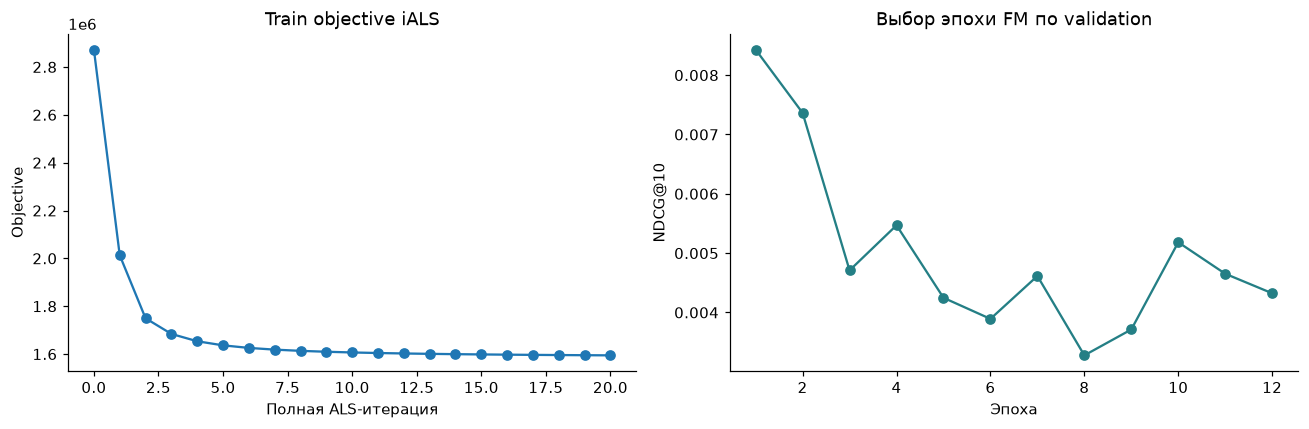

In [17]:
display(runner.validation_ablations()[['model','ndcg@10','recall@10','coverage@10','params']])
selected_table = pd.DataFrame([{'model': name, 'validation_ndcg@10': row['ndcg@10'], 'validation_recall@10': row['recall@10'], 'params': row['params'], 'selected_epochs': row.get('selected_epochs')} for name,row in runner.journal['selected'].items()])
display(selected_table)
selected_table.to_csv(ROOT/'results/selected_hyperparameters.csv',index=False)
fig, axes = plt.subplots(1,2,figsize=(12,4))
axes[0].plot(runner.best_models['IALS'].objective_history_,marker='o',label='iALS')
axes[0].set(title='Train objective iALS',xlabel='Полная ALS-итерация',ylabel='Objective')
fm_history = pd.DataFrame(runner.best_models['FM'].history_)
axes[1].plot(fm_history.epoch,fm_history.validation_metric,marker='o',color='#247f85')
axes[1].set(title='Выбор эпохи FM по validation',xlabel='Эпоха',ylabel='NDCG@10')
fig.tight_layout(); fig.savefig(ROOT/'results/figures/training.png',bbox_inches='tight'); plt.show()

## 5. Результаты на test

Модели обучены на train + validation с выбранными настройками.
Средние пересчитаны, каталог сохранён, известные товары исключены.
У FM используется выбранное на validation число эпох.
У всех моделей и дополнительных вариантов один test-протокол.

In [18]:
final = runner.final_test()
test_table = pd.DataFrame(final['rows'])
display(pd.Series(final['protocol'],name='Оценка на test'))
assert test_table.protocol.nunique() == 1
primary_models = ['ItemKNN', 'IALS', 'EASE', 'FM', 'CustomALS']
display(test_table[test_table.model.isin(primary_models)][['model','ndcg@10','recall@10','coverage@10','fit_seconds','params']].sort_values('ndcg@10',ascending=False).reset_index(drop=True))
display(pd.DataFrame(final['paired_bootstrap']))

FINAL refit/evaluate: Popularity


  NDCG@10=0.019339, Recall@10=0.031913


FINAL refit/evaluate: ItemKNN


  NDCG@10=0.024049, Recall@10=0.040343


FINAL refit/evaluate: IALS


...

FINAL refit/evaluate: ALS_custom_matched


  NDCG@10=0.018105, Recall@10=0.029926


heldout_users                                        2227
heldout_events                                       3737
heldout_positive_events                              3058
evaluated_users                                      1894
excluded_users_no_eligible_positive_or_candidates     333
relevant_pairs                                       3058
fallback_users_without_positive_history                 0
candidate_catalog                                    4849
Name: Оценка на test, dtype: int64

,model,ndcg@10,recall@10,coverage@10,fit_seconds,params
0,EASE,0.026974,0.042529,0.157558,1.016158,{'regularization': 1000.0}
1,IALS,0.025365,0.047284,0.125180,11.231951,"{'factors': 32, 'regularization': 0.01, 'alpha..."
2,ItemKNN,0.024049,0.040343,0.346463,0.072118,"{'k': 100, 'shrinkage': 50}"
3,CustomALS,0.018105,0.029926,0.121881,11.059007,"{'factors': 32, 'regularization': 0.01, 'alpha..."
4,FM,0.007579,0.013082,0.004537,0.157969,"{'factors': 32, 'learning_rate': 0.003, 'regul..."


,comparison,left,right,mean_ndcg_difference,ci95_low,ci95_high,unit,bootstrap_samples
0,metadata_effect,FM,FM_ID_only_matched,-0.004944,-0.008655,-0.001074,user,2000
1,custom_target_matched_effect,ALS_custom_matched,IALS,-0.007260,-0.011014,-0.003583,user,2000
2,personal_calibration_effect,ALS_custom_matched,ALS_absolute_matched,-0.001884,-0.003406,-0.000414,user,2000


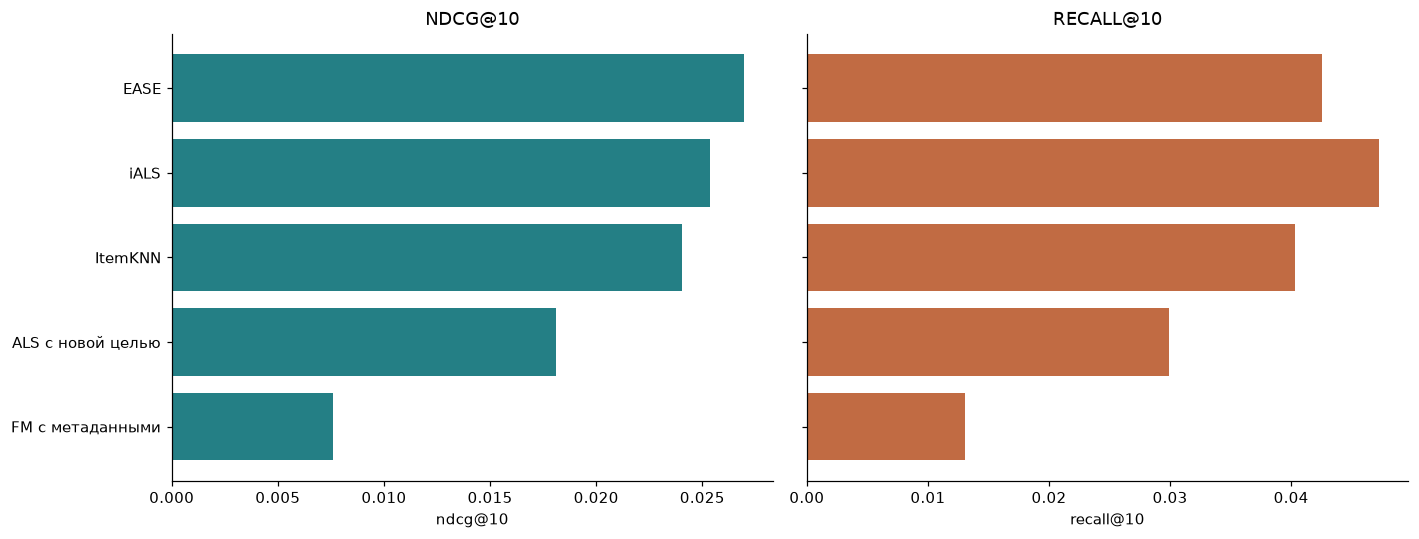

,model,uid,rank,title
0,ItemKNN,2,1,"Donner Guitar Delay Pedal, Yellow Fall Analog ..."
1,ItemKNN,2,2,BEHRINGER ULTRA CHORUS UC200 and BEHRINGER VIN...
2,ItemKNN,2,3,Behringer NOISE REDUCER NR300 Ultimate Noise R...
3,ItemKNN,2,4,Behringer PSU-SB - General-Purpose DC 9V Power...
4,ItemKNN,2,5,D'Addario Guitar Cable - Guitar Patch Cable - ...
5,ItemKNN,2,6,Donner 12 Inch Guitar Patch Cable Guitar Effec...
6,ItemKNN,2,7,Behringer VINTAGE DELAY VD400 Vintage Analog D...
7,ItemKNN,2,8,GLS Audio Instrument Cable - Amp Cord for Bass...
8,ItemKNN,2,9,"Compressor Guitar Pedal, Mini Effect Processor..."
9,ItemKNN,2,10,Ernie Ball Mondo Slinky Nickelwound Electric G...


In [19]:
ordered = test_table[test_table.model.isin(primary_models)].sort_values('ndcg@10')
model_names = {'IALS': 'iALS', 'FM': 'FM с метаданными', 'CustomALS': 'ALS с новой целью'}
fig, axes = plt.subplots(1,2,figsize=(13,5),sharey=True)
for ax, metric, color in [(axes[0],'ndcg@10','#247f85'),(axes[1],'recall@10','#c16b43')]:
    ax.barh(ordered.model.replace(model_names),ordered[metric],color=color)
    ax.set(xlabel=metric,title=metric.upper())
fig.tight_layout(); fig.savefig(ROOT/'results/figures/test_comparison.png',bbox_inches='tight'); plt.show()
examples=[]
for label in ['ItemKNN','IALS','EASE','FM','CustomALS']:
    user=final['example_user_ids'][0]
    for rank,iid in enumerate(final['example_recommendations'][label][0],1):
        examples.append({'model':label,'uid':user,'rank':rank,'title':data.metadata.iloc[iid].title})
display(pd.DataFrame(examples))

## 6. Выводы

Для разностей NDCG рассчитаны парные bootstrap-интервалы:
2 000 повторных выборок пользователей, seed 42.
Они учитывают различия между пользователями, но не разные запуски обучения или датасеты.

Обучение проверено с одним seed и ограниченным набором настроек.
FM учится только на оценённых товарах, поэтому качество на полном каталоге может быть ниже.
Эти метрики не показывают эффект рекомендаций в реальном сервисе.

In [20]:
mandatory = test_table[test_table.model.isin(['ItemKNN','IALS','EASE','FM','CustomALS'])]
best = mandatory.sort_values('ndcg@10',ascending=False).iloc[0]
best_recall = mandatory.sort_values('recall@10',ascending=False).iloc[0]
lines = [f"**Лучший NDCG@10 — {best['model']}: {best['ndcg@10']:.5f}.**", f"Лучший Recall@10 — {best_recall['model']}: {best_recall['recall@10']:.5f}."]
lines.append('Параметры ' + best['model'] + ': `' + json.dumps(best['params'], ensure_ascii=False) + '`.')
comparison_names = {
    'metadata_effect': 'FM с метаданными − FM только с ID',
    'custom_target_matched_effect': 'Новая цель ALS − бинарная',
    'personal_calibration_effect': 'Поправка на шкалу пользователя − без поправки',
}
for row in final['paired_bootstrap']:
    delta=row['mean_ndcg_difference']; low=row['ci95_low']; high=row['ci95_high']
    evidence='интервал включает ноль' if low<=0<=high else 'интервал не включает ноль'
    lines.append(f"{comparison_names[row['comparison']]}: ΔNDCG@10 = {delta:+.5f}, 95% ДИ [{low:+.5f}; {high:+.5f}]; {evidence}.")
fastest=mandatory.sort_values('fit_seconds').iloc[0]
lines.append(f"Быстрее всех обучается {fastest['model']}: {fastest['fit_seconds']:.2f} с на этом CPU.")
display(Markdown('\n\n'.join(lines)))

**Лучший NDCG@10 — EASE: 0.02697.**

Лучший Recall@10 — IALS: 0.04728.

Параметры EASE: `{"regularization": 1000.0}`.

FM с метаданными − FM только с ID: ΔNDCG@10 = -0.00494, 95% ДИ [-0.00866; -0.00107]; интервал не включает ноль.

Новая цель ALS − бинарная: ΔNDCG@10 = -0.00726, 95% ДИ [-0.01101; -0.00358]; интервал не включает ноль.

Поправка на шкалу пользователя − без поправки: ΔNDCG@10 = -0.00188, 95% ДИ [-0.00341; -0.00041]; интервал не включает ноль.

Быстрее всех обучается ItemKNN: 0.07 с на этом CPU.

**ВЫВОД**: **EASE — лучший по NDCG@10, iALS — по Recall@10.** ItemKNN быстрее обучается и даёт самый широкий охват каталога.

По основной метрике для этой задачи выбираю EASE. Метаданные FM и новая цель ALS качество не улучшили. В этом эксперименте более сложные признаки и целевой сигнал не дали преимущества перед простыми методами.